In [1]:
%pip install -r requirements-offline.txt --quiet

/Users/utarn/projects/datascience-metrology/.check-env/bin/python: No module named pip


Note: you may need to restart the kernel to use updated packages.


# Solution — Module M4: กราฟที่สื่อสารได้

เปิดเผยหลังจบแล็บ — เทียบกับของตัวเอง โฟกัสที่การเลือกกราฟและการอ่านผล

In [2]:
import pandas as pd
from pathlib import Path


def repo_root() -> Path:
    """หา repo root โดยไล่ขึ้นจาก cwd."""
    for p in (Path.cwd(), *Path.cwd().parents):
        if (p / "requirements-offline.txt").exists():
            return p
    raise SystemExit(
        "ไม่พบ repo root — เปิด JupyterLab จาก repo root (uv run jupyter lab)")

PENG = repo_root() / "datasets" / "palmer_penguins"
GAP = repo_root() / "datasets" / "gapminder"

penguins = pd.read_csv(PENG / "penguins.csv").dropna()
gapminder = pd.read_csv(GAP / "gapminderDataFiveYear.csv")
import matplotlib.pyplot as plt  # noqa: E402
plt.rcParams["font.family"] = [
    "DejaVu Sans", "Noto Sans Thai", "Leelawadee UI", "Tahoma",
]


## ส่วนที่ 1 — เลือกกราฟให้ตรงคำถาม

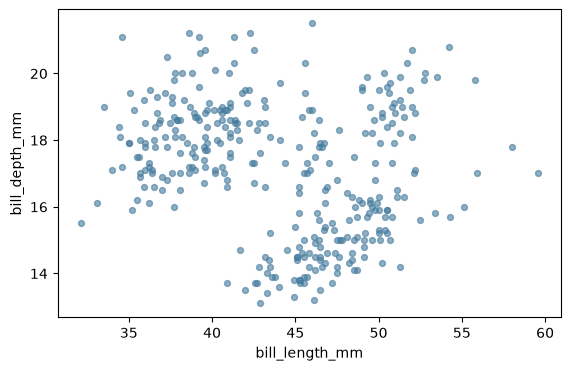

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.scatter(penguins["bill_length_mm"], penguins["bill_depth_mm"],
           s=18, alpha=0.6, color="#457b9d")
ax.set_xlabel("bill_length_mm")
ax.set_ylabel("bill_depth_mm")
plt.show()

**1.1** ดูไม่มีความสัมพันธ์ชัด — จุดกระจายเป็นเมฆกว้าง

**1.2** (การคาดคะเนขึ้นกับผู้เรียน — ตัวอย่าง: "น่าจะแยกเป็นกลุ่มชัดขึ้น")

## ส่วนที่ 2 — สีคือตัวแปรที่สาม

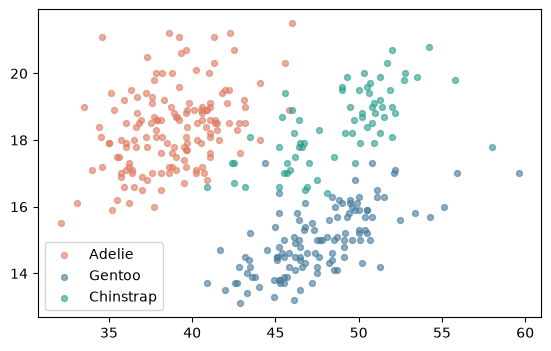

In [4]:
colors = {"Adelie": "#e07a5f", "Gentoo": "#457b9d",
          "Chinstrap": "#2a9d8f"}

fig, ax = plt.subplots(figsize=(6.5, 4))
for species_name, color in colors.items():
    mask = penguins["species"] == species_name
    subset = penguins[mask]
    ax.scatter(subset["bill_length_mm"], subset["bill_depth_mm"],
               s=18, alpha=0.6, color=color, label=species_name)
ax.legend()
plt.show()

**2.1** คำตอบมักต่างจากที่เดาจากกราฟรวม: ภายในแต่ละชนิด ปาก**ยาวกว่า
ลึกกว่า**จริง (Adelie/Chinstrap ชัด Gentoo อ่อน) — แต่เมื่อรวมทั้งสามชนิด
Gentoo (ปากสั้นกว่า ลึกน้อย) ดันภาพรวมให้เหมือนไม่สัมพันธ์

ประเด็นสำคัญ: **ความสัมพันธ์ในกลุ่มย่อยอาจต่างจากภาพรวม** — นี่คือเหตุผล
ที่ก่อนสรุปจาก scatter ต้องถามเสมอว่า "มีกลุ่มอะไรซ่อนอยู่ไหม

## ส่วนที่ 3 — bar จาก gapminder

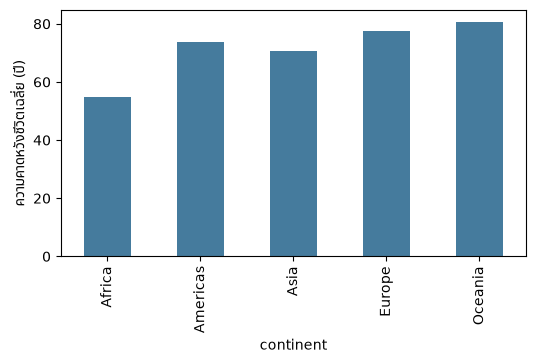

In [5]:
year2007 = gapminder[gapminder["year"] == 2007]
by_continent = year2007.groupby("continent")["lifeExp"].mean()

fig, ax = plt.subplots(figsize=(6, 3.2))
by_continent.plot.bar(ax=ax, color="#457b9d")
ax.set_ylabel("ความคาดหวังชีวิตเฉลี่ย (ปี)")
plt.show()

**3.1** Oceania สูงสุด (~74 ปี) · Africa ต่ำสุด (~53 ปี) — ต่าง ~21 ปี
ไม่ควรพูดเป็น "หลายเท่า" เพราะค่าเฉลี่ยชีวิตไม่ได้เริ่มจากศูนย์ และค่าเฉลี่ย
ทวีปซ่อนประเทศใหญ่ตัวจบ (ดู Sierra Leone vs Mauritius ใน Africa เอง)

## ส่วนที่ 4 — line หลายเส้น

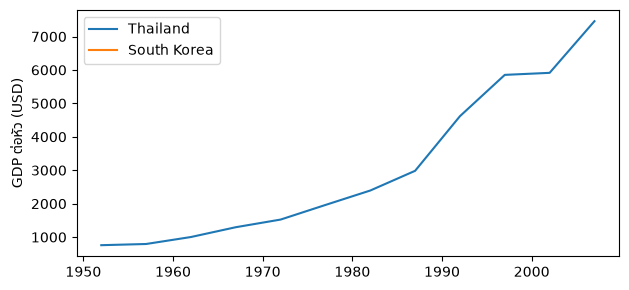

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.2))
for country_name in ["Thailand", "South Korea"]:
    one = gapminder[gapminder["country"] == country_name]
    ax.plot(one["year"], one["gdpPercap"], label=country_name)
ax.legend()
ax.set_ylabel("GDP ต่อหัว (USD)")
plt.show()

**4.1** ช่วง 1952–1975 เส้นสองประเทศไล่กันแน่น — หลัง ~1985 เกาหลีใต้
เร่งแซงขึ้นสูงมาก (กราฟเส้นเห็น "จุดพลิก" ได้ทันที แต่ในตารางต้องเรียง
เทียบทีละแถวจึงเห็น)

## ส่วนที่ 5 — ส่งออกภาพ

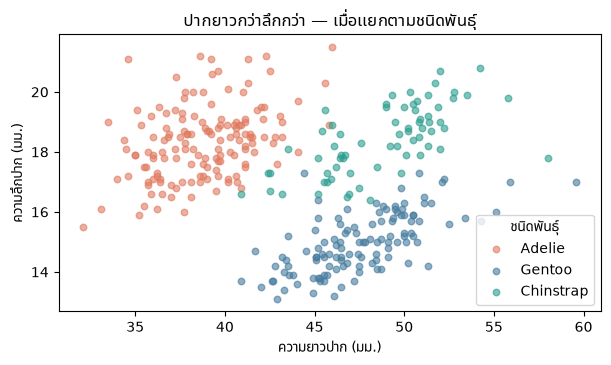

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.6))
for species_name, color in colors.items():
    mask = penguins["species"] == species_name
    subset = penguins[mask]
    ax.scatter(subset["bill_length_mm"], subset["bill_depth_mm"],
               s=22, alpha=0.6, color=color, label=species_name)
ax.legend(title="ชนิดพันธุ์")
ax.set_xlabel("ความยาวปาก (มม.)")
ax.set_ylabel("ความลึกปาก (มม.)")
ax.set_title("ปากยาวกว่าลึกกว่า — เมื่อแยกตามชนิดพันธุ์")
plt.savefig("my_chart.png", dpi=150, bbox_inches="tight")
plt.show()

ตรวจกับเช็คลิสต์ 4 ข้อ: หัวเรื่องบอกข้อสรุป ✓ · หน่วย (มม.) ทั้งสองแกน ✓ ·
legend มี title ✓ · scatter ไม่มีกฎฐานศูนย์ (เป็นกราฟจุด) ✓

ไฟล์ `my_chart.png` อยู่โฟลเดอร์เดียวกับโน้ตบุ๊ก — เปิดดูก่อนแนบรายงาน

ภาพนี้คือ**รูปแรกจากข้อมูลจริง**ของผู้เรียน — แบบฝึกนี้ปิดวันที่ 1
ก่อนพัก ให้แต่ละคนมีไฟล์ PNG ของตัวเองติดมือกลับบ้านหนึ่งไฟล์
